In [22]:
# Gurobi version--- the SI: reliability and maintenance version
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
from gurobipy import Model as GurobiModel, GRB
from gurobipy import quicksum



# define the parameters
PARAMS = {
    'P': 10,        # number of caissons
    'T': 60,      # horizon
    'Cmax':5,      # maximum number of tasks of one cluster
    'window_size': 10,   # window size
    'advanced': 3,          # advanced time
    'K': 5.993,         # leakage coefficient
    'alpha': 5,    # unit cost of advancing one day
    'beta': 10,       # unit cost of delaying one day
    'Cs':100      # Unit setup cost
}   

# initialize the random values
random.seed(42)
# alpha_values = [round(random.uniform(0.03, 0.08), 3) for _ in range(PARAMS['P'])]
alpha_values = [round(random.uniform(0.01, 0.05), 6) for _ in range(PARAMS['P'])]   # degradation rate for each caisson
random.seed(42)
initial_p_values = [round(random.uniform(3.2, 3.5), 2) for i in range(PARAMS['P'])]
print("alpha values:", alpha_values)

def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
    """extract maintenance periods from data"""
    
    maintenance_periods = {}
    D_min_dict = {}
    D_max_dict = {}
    
    print("\n===== 从数据中提取维修周期 =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
    print("-" * 80)
    
    for caisson_id in sorted(df['CSEM'].unique()):
        # 步骤1：筛选该caisson的所有'x'操作
        caisson_tasks = df[
            (df['CSEM'] == caisson_id) & 
            (df['OPERATION'] == 'x')
        ].sort_values('DATE')
        
        # Step 2: Check if there are at least 2 tasks
        if len(caisson_tasks) < 2:
            default_period = PARAMS['window_size']  # ← 新增
            maintenance_periods[caisson_id] = default_period
            D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
            D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
            print(f"... {default_period:<12.2f} ...")  
            continue
        
        # 步骤3：计算相邻任务之间的间隔
        intervals = []
        for i in range(1, len(caisson_tasks)):
            interval = caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE']
            intervals.append(interval)
        
        # 步骤4：使用中位数作为维修周期
        maintenance_period = np.mean(intervals)
        maintenance_periods[caisson_id] = maintenance_period
        
        # 步骤5：计算D_min和D_max
        D_min_dict[caisson_id] = int(np.ceil(maintenance_period * d_min_ratio))
        D_max_dict[caisson_id] = int(np.ceil(maintenance_period * d_max_ratio))
        
        # 步骤6：打印结果
        interval_min = min(intervals)
        interval_max = max(intervals)
        interval_range = f"[{interval_min}, {interval_max}]"
        
        print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} "
              f"{maintenance_period:<12.2f} {D_min_dict[caisson_id]:<10} {D_max_dict[caisson_id]:<10}")
    
    print("===== 提取完成 =====\n")
    
    return maintenance_periods, D_min_dict, D_max_dict


def clustering_CR(df_window, window_size, window_start, global_task_count, full_df, D_min_dict, D_max_dict):
    """Grouping model implemented with Gurobi. Function signature and variable names
    are kept identical to the original docplex version so it can be drop-in replaced.
    """

    # add preprocessing here
    if df_window.empty or window_size < 1:
        print(f"warning: window {window_start} has no tasks or window size is invalid")
        return df_window  # return the original dataframe if no tasks in the window

    N = df_window.shape[0]  # number of tasks in the window

    mdl = GurobiModel('Dynamic_Window_Clustering')
    mdl.setParam('OutputFlag', 0)  # turn off solver output by default

    # define the variables
    data_pos_num = window_size + 1
    # theta[n,t]
    theta = mdl.addVars(N, data_pos_num, vtype=GRB.BINARY, name='theta')
    # CS[t]
    CS = mdl.addVars(data_pos_num, lb=0.0, vtype=GRB.CONTINUOUS, name='CS')
    # y[t]
    y = mdl.addVars(data_pos_num, vtype=GRB.BINARY, name='y')

    # convenience: access as theta[n, t]

    a = [0] * N
    b = [0] * N

    # every task must be assigned to one cluster
    for n in range(N):
        mdl.addConstr(theta.sum(n, '*') == 1, name=f"assign_task_{n}")

    # maximum capacity in each cluster
    for t in range(data_pos_num):
        mdl.addConstr(theta.sum('*', t) <= PARAMS['Cmax'], name=f"cap_{t}")

    # define the possible advanced or delayed range for each task: local time
    for n in range(N):
        local_time = int(df_window.iloc[n]['window_time'])
        a[n] = int(max(0, local_time - PARAMS['advanced']))
        b[n] = int(min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])]) - 2))

    # cluster center constraints
    for n in range(N):
        for t in range(data_pos_num):
            # t * theta[n,t] + a[n] * (1 - theta[n,t]) >= a[n]
            # equivalently: (t - a[n]) * theta[n,t] >= 0  when rearranged, but keep original form for clarity
            mdl.addConstr(t * theta[n, t] + a[n] * (1 - theta[n, t]) >= a[n], name=f"lb_range_n{n}_t{t}")
            mdl.addConstr(t * theta[n, t] + b[n] * (1 - theta[n, t]) <= b[n], name=f"ub_range_n{n}_t{t}")


    # ensure y[t] indicates whether cluster t is used
    M = PARAMS['Cmax']
    for t in range(data_pos_num):
        task_count = theta.sum('*', t)
        # task_count >= 1 - M*(1 - y[t])  <=> task_count + M*(1-y[t]) >= 1
        mdl.addConstr(task_count + M * (1 - y[t]) >= 1, name=f"activate_lb_{t}")
        # task_count <= M * y[t]
        mdl.addConstr(task_count <= M * y[t], name=f"activate_ub_{t}")

    # setup cost (same expression as original)
    setup_cost = PARAMS['Cs'] * (theta.sum() - y.sum())

    # build cost matrix and CP_total
    cost_matrix = {}
    for n in range(N):
        local_time_n = int(df_window.iloc[n]['window_time'])
        for t in range(data_pos_num):
            deviation = t - local_time_n
            if deviation > 0:
                cost_matrix[(n, t)] = PARAMS['beta'] * deviation
            elif deviation < 0:
                cost_matrix[(n, t)] = PARAMS['alpha'] * (-deviation)
            else:
                cost_matrix[(n, t)] = 0

    # total cost (linear expression)
    CP_total = quicksum(cost_matrix[(n, t)] * theta[n, t] for n in range(N) for t in range(data_pos_num))

    # maintenance constraints (skip for first window)
    for n in range(N):
        row = df_window.iloc[n]
        caisson = int(row['CSEM'])

        if window_start == 0:
            print(f"  Caisson {caisson}: skip constraint (first window)")
            continue

        prev_rows = full_df[
            (full_df['CSEM'] == caisson) &
            (full_df['CENTER'] < row['DATE']) &
            (full_df['OPERATION'] == 'x')
        ].sort_values('CENTER')

        if prev_rows.empty:
            prev_center = 0
            print(f"  Caisson {caisson}: first task ever, prev_center=0")
            continue

        prev_center = int(prev_rows.iloc[-1]['CENTER'])
        print(f"  Caisson {caisson}: prev_center={prev_center}")

        # t_now_local = sum(t * theta[n,t])
        t_now_local = quicksum(t * theta[n, t] for t in range(data_pos_num))
        # t_now_global = t_now_local + window_start
        # Add maintenance distance constraints: d_min <= t_now_global - prev_center <= d_max
        d_min_i = D_min_dict[caisson]
        d_max_i = D_max_dict[caisson]

        mdl.addConstr(t_now_local + window_start - prev_center >= d_min_i, name=f"dmin_n{n}")
        mdl.addConstr(t_now_local + window_start - prev_center <= d_max_i, name=f"dmax_n{n}")

    # objective
    obj = setup_cost - CP_total
    mdl.setObjective(obj, GRB.MAXIMIZE)

    # optimize
    mdl.optimize()

    if mdl.status != GRB.OPTIMAL and mdl.status != GRB.TIME_LIMIT and mdl.status != GRB.SUBOPTIMAL:
        print(f"Failed to solve the problem: status {mdl.status}")
        return None

    # result processing
    centers = {}
    for n in range(N):
        for t in range(data_pos_num):
            val = theta[n, t].X
            if val is not None and round(val) == 1:
                centers[n] = t + window_start
                break

    index_n_list = df_window.INDEX.tolist()

    for n in range(len(index_n_list)):
        for t in range(data_pos_num):
            if round(theta[n, t].X) == 1:
                df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

    # model stats (similar info to docplex prints)
    print(f"Model stats: {mdl.NumVars} vars, {mdl.NumConstrs} cons")
    print(f"Objective value: {mdl.ObjVal if hasattr(mdl, 'ObjVal') else mdl.getObjective().getValue()}")

    return df_window


def calculate_gas_leakage_before(df, T):
    total_leakage = 0

    for csem in df['CSEM'].unique():
        # filter the data for the current CSEM
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x']
        y_operations = csem_data[csem_data['OPERATION'] == 'y']
        alpha = alpha_values[csem]

        # deal with the 'x' operations in the middle
        for i in range(1, len(x_operations)):
            current_x = x_operations.iloc[i]
            previous_x = x_operations.iloc[i - 1]
            center_diff = current_x['DATE'] - previous_x['DATE'] - 1
            total_leakage += center_diff * alpha * PARAMS['K']

        # deal with the first 'x' operation
        if not x_operations.empty:
            first_x = x_operations.iloc[0]
            total_leakage += first_x['DATE'] * alpha * PARAMS['K']

        # deal with the last 'x' operation (special handling)
        last_x = x_operations.iloc[-1]
        last_x_end = last_x['DATE'] + 1  # end of last maintenance day
        
        if not y_operations.empty:
            # if there is a 'y' operation
            y_center = y_operations['DATE'].iloc[0]
            leak_time = max(0, y_center - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']
        else:
            # if there is no 'y' operation
            leak_time = max(0, T - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']

    return total_leakage


# function to calculate the gas leakage after clustering
def calculate_gas_leakage_after(df, T):
    total_leakage = 0

    for csem in df['CSEM'].unique():
        # filter the data for the current CSEM
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x']
        y_operations = csem_data[csem_data['OPERATION'] == 'y']
        alpha = alpha_values[csem]

        # deal with the 'x' operations in the middle
        for i in range(1, len(x_operations)):
            current_x = x_operations.iloc[i]
            previous_x = x_operations.iloc[i - 1]
            center_diff = current_x['CENTER'] - previous_x['CENTER'] - 1
            total_leakage += center_diff * alpha * PARAMS['K']

        # deal with the first 'x' operation
        if not x_operations.empty:
            first_x = x_operations.iloc[0]
            total_leakage += first_x['CENTER'] * alpha * PARAMS['K']

    
        # deal with the last 'x' operation (special handling)
        last_x = x_operations.iloc[-1]
        last_x_end = last_x['CENTER'] + 1  # end of last maintenance day
        
        if not y_operations.empty:
            # if there is a 'y' operation
            y_center = y_operations['DATE'].iloc[0]
            leak_time = max(0, y_center - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']
        else:
            # if there is no 'y' operation
            leak_time = max(0, T - last_x_end)
            total_leakage += leak_time * alpha * PARAMS['K']

    return total_leakage

def main(window_size):
    """Main function"""
    
    df = pd.read_csv('maintenance_plan_new.csv')   #original SI planning 
    # df = pd.read_csv('maintenance_plan_uncertainPercentage.csv') 
    df_init = df.copy()
    df_history_list = []
    df_history_list.append(df_init)
    sliding_windows_starts = []
    sliding_windows_ends = []
    # df['CENTER'] = 0  # initialize the center column
    df['CENTER'] = df['DATE']  # initialize the center column

    # 新增这7行
    maintenance_periods, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df=df, d_min_ratio=0.5, d_max_ratio=1.5)
    PARAMS['D_min'] = D_min_dict
    PARAMS['D_max'] = D_max_dict


    # 全局变量：记录每一天的任务数量
    global_task_count = [0] * PARAMS['T'] * 2
    window_start = 0

    while window_start <= PARAMS['T']:
        # dynamic window selection
        window_end = window_start + window_size
        if window_end > PARAMS['T']:
            window_end = PARAMS['T']
        
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')  

        window_df = df.loc[mask].copy()

        # task local time conversion
        window_df['window_time'] = window_df['DATE'] - window_start

        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        # clustering these first tasks in the window
        clustered_df = clustering_CR(first_tasks, window_size, window_start, global_task_count, df, D_min_dict, D_max_dict)
        
        if clustered_df is not None:
            # update the center column of original dataframe
            center_map = clustered_df.set_index('INDEX')['CENTER']

            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)

            # update the secondary tasks time
            update_secondary_tasks(df, clustered_df, window_start, window_end)


        # slide the window to the next task that haven't been clustered yet   !!! new version
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                # 获取该 caisson 在当前窗口内的任务
                tasks = df[
                    (df['CSEM'] == caisson) & 
                    (df['OPERATION'] == 'x') &
                    (df['DATE'].between(window_start, window_end))
                ].sort_values('DATE')

                # 如果有至少两个任务，取第二个的 DATE
                if len(tasks) > 1:
                    second_date = tasks.iloc[1]['DATE']
                    second_dates.append(second_date)

        # 如果有至少一个有效的 second_date，就更新窗口起点
        if second_dates:
            window_start = min(second_dates)
        else:
            # fallback：维持旧逻辑，或推进一整个窗口长度
            window_start = window_start + window_size  # 或者 clustered_df['CENTER'].max() + 1
        # ---------------

        df_history_list.append(df.copy())

        if window_end>=PARAMS['T']:
            break

        df.loc[df['INDEX'].isin(center_map.index), 'DATE'] = df['INDEX'].map(center_map)
    # Updates the center column of the RE operation, which will not be grouped
    df.loc[df['OPERATION'] == "y", 'CENTER'] = df.loc[df['OPERATION'] == "y", 'DATE']

    # Processing of the remaining tasks that are not assigned to a center and cannot be updated
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == 0)
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']


        # ====== 新增：检查最终任务间隔（诊断用）======
    df_sorted = df[df['OPERATION']=='x'].sort_values(['CSEM', 'CENTER'])
    df_sorted['PREV_CENTER'] = df_sorted.groupby('CSEM')['CENTER'].shift(1)
    df_sorted['GAP'] = df_sorted['CENTER'] - df_sorted['PREV_CENTER']
    print("\n===== 最终任务间隔分析 =====")
    print(df_sorted[['CSEM','CENTER','PREV_CENTER','GAP']].head(20))
    print(f"gap min: {df_sorted['GAP'].min()}, gap max: {df_sorted['GAP'].max()}")
    print("===== 分析结束 =====\n")
    # ====== 诊断代码结束 ======
    
    
    # result verification
    # assert df['CENTER'].notna().all(), "Some tasks are not clustered"
    return df, df_history_list, sliding_windows_starts, sliding_windows_ends

# # function to update the secondary tasks date of each window
# def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
#     """Update the secondary tasks time"""
#     for caisson in clustered_df["CSEM"].unique():
#         # get the tasks in the same caisson
#         tasks = main_df[
#             (main_df['CSEM'] == caisson) & 
#             (main_df['DATE'].between(window_start, window_end)) 
#         ]
#         tasks = main_df[
#             (main_df['CSEM'] == caisson) & 
#             (main_df['DATE'].between(window_start, window_end)) & 
#             (main_df['OPERATION'] == 'x')
#         ]
        
#         if len(tasks) > 1:
#             # get the second task index
#             second_idx = tasks.index[1]
            
#             # get the previous center time amd calculate the new time for the second task
#             center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            
#             # calulate the new time
#             alpha = alpha_values[caisson]
#             # new_date = int(center_time + 1 + (3.5-3.2)/alpha)
#             new_date = int(center_time + 1)
            
#             # update the time
#             main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date



def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
    for caisson in clustered_df["CSEM"].unique():
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) & 
            (main_df['OPERATION'] == 'x')
        ].sort_values('DATE')
        
        if len(tasks) >= 2:
            first_task = tasks.iloc[0]
            second_idx = tasks.index[1]
            
            orig_first = first_task['DATE']
            first_center = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            delta = first_center - orig_first  # 移动量
            
            orig_second = tasks.iloc[1]['DATE']
            new_date = min(window_end, orig_second + delta)  # +约束
            
            main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date
            print(f"Caisson{caisson}: first {orig_first}→{first_center} (delta={delta}), second {orig_second}→{new_date}")


result_df, df_history_list, sliding_windows_starts, sliding_windows_ends = main(PARAMS['window_size'])
result_df.to_csv("clustering_result.csv", index=False)

alpha values: [0.035577, 0.011, 0.021001, 0.018928, 0.039459, 0.037068, 0.045687, 0.013478, 0.026877, 0.011192]

===== 从数据中提取维修周期 =====
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
0          4          [13, 13]             13.00        7          20        
1          7          [7, 7]               7.00         4          11        
... 10.00        ...
3          2          [21, 21]             21.00        11         32        
4          7          [7, 7]               7.00         4          11        
5          6          [9, 9]               9.00         5          14        
6          1          [42, 42]             42.00        21         63        
7          3          [17, 17]             17.00        9          26        
8          7          [7, 7]               7.00         4          11        
9          3          [14, 14]             14.00        7   

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_16721/3100305365.py:351: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_16721/3100305365.py:351: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

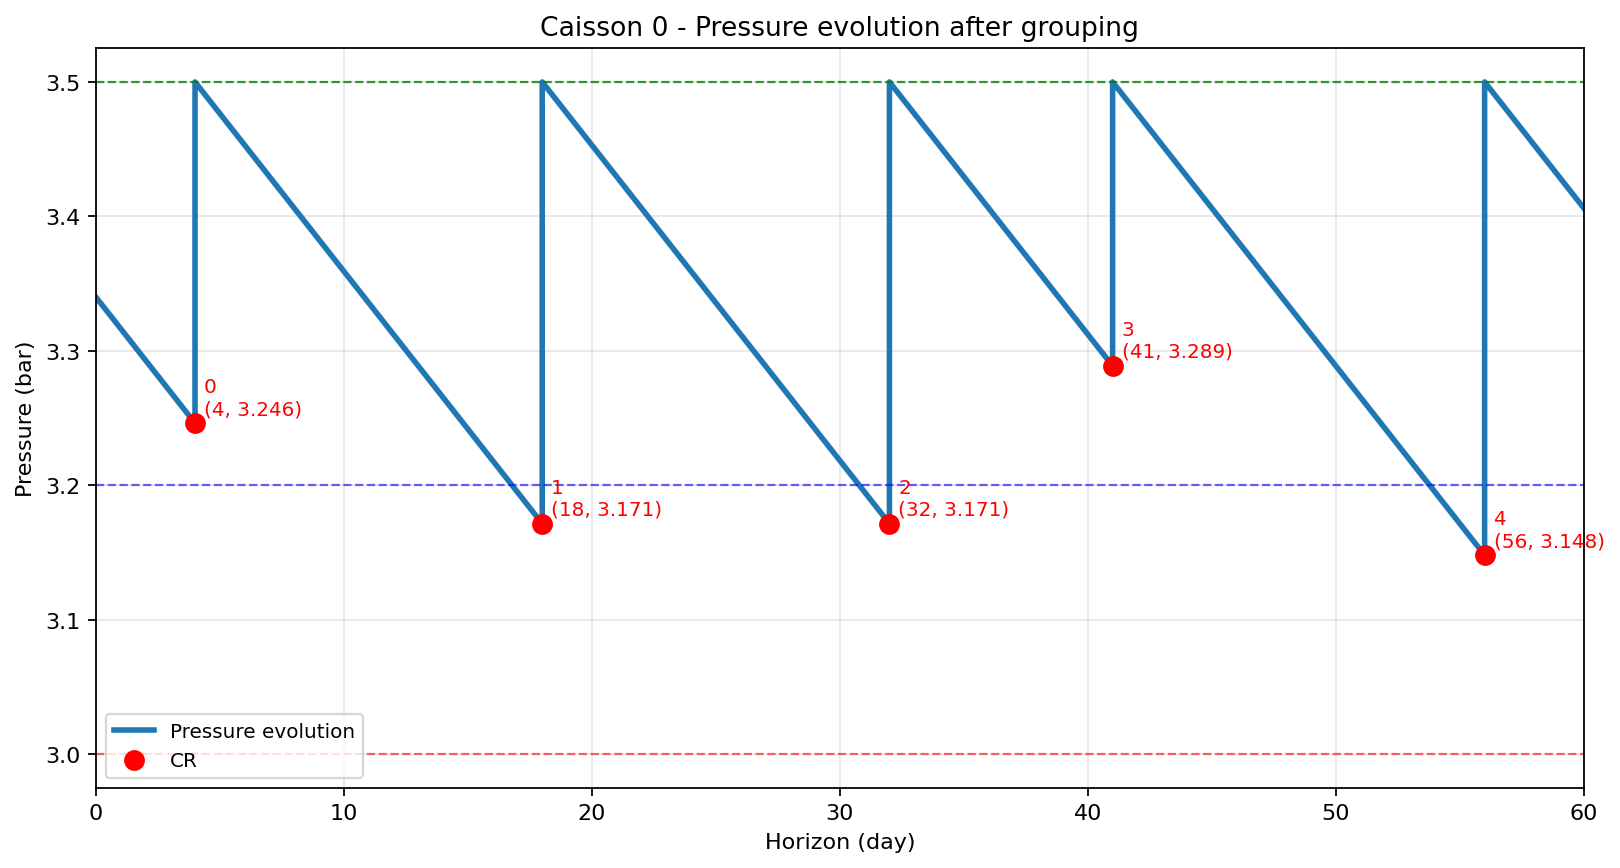

图已保存到：output/caisson_0_pressure_center_based.png


In [31]:
# draw pressure profile if grouping results are applied
# here，nominal pressure and nominal alpha

import pandas as pd
import matplotlib.pyplot as plt
import os

# =========================
# 1. 读取聚类后的结果
# =========================
planning = pd.read_csv("clustering_result.csv")  
T = 60

# =========================
# 2. 指定要画的 CSEM
# =========================
caisson_idx = 0

tasks = planning[(planning["CSEM"] == caisson_idx) & (planning["OPERATION"] == "x")].copy()
if tasks.empty:
    raise ValueError(f"没有找到 CSEM={caisson_idx} 的 x 任务")

# 关键：按 CENTER 排，而不是 DATE
tasks = tasks.sort_values("CENTER").reset_index(drop=True)

# =========================
# 3. 取得 alpha 和初始压力
# =========================
# 如果表里已经有 ALPHA / INITIALP，就直接读
# 否则用你主程序里的 alpha_values / initial_p_values
alpha = float(tasks.iloc[0]["ALPHA"])
initial_p = float(tasks.iloc[0]["INITIALP"])

# =========================
# 4. 构造“按 CENTER 维修”的压力轨迹
# =========================
x = [0]
y = [initial_p]

current_day = 0
current_p = initial_p

task_days = []
task_pressures_before = []
task_labels = []

for _, row in tasks.iterrows():
    task_day = int(row["CENTER"])
    task_index = int(row["INDEX"])

    # 先线性下降到该次 CENTER
    p_before_task = current_p - alpha * (task_day - current_day)

    # 到达维修时刻前的压力点
    x.append(task_day)
    y.append(p_before_task)

    # 同一天垂直跳升到 3.5
    x.append(task_day)
    y.append(3.5)

    # 记录维修点信息
    task_days.append(task_day)
    task_pressures_before.append(p_before_task)
    task_labels.append(task_index)

    # 更新状态
    current_day = task_day
    current_p = 3.5

# 最后一个维修后继续下降到 T
if current_day < T:
    final_p = current_p - alpha * (T - current_day)
    x.append(T)
    y.append(final_p)

# =========================
# 5. 画图
# =========================
fig, ax = plt.subplots(figsize=(12, 6), dpi=160)

# 连续折线；同一个 x 对应两个 y，会形成竖直跳变
ax.plot(x, y, color="#1f77b4", linewidth=2.5, label="Pressure evolution")

# 标出每次维修前的压力点
ax.scatter(task_days, task_pressures_before, color="red", s=70, zorder=5, label="CR")

for day, p_before, idx in zip(task_days, task_pressures_before, task_labels):
    ax.annotate(
        f"{idx}\n({day}, {p_before:.3f})",
        xy=(day, p_before),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=9,
        color="red"
    )

# 参考线
ax.axhline(3.5, color="green", linestyle="--", linewidth=1, alpha=0.8)
# 如果你还想保留3.2参考线，可以画，但它不再是触发逻辑
ax.axhline(3.0, color="red", linestyle="--", linewidth=1, alpha=0.6)
ax.axhline(3.2, color="blue", linestyle="--", linewidth=1, alpha=0.6)

ax.set_title(f"Caisson {caisson_idx} - Pressure evolution after grouping")
ax.set_xlabel("Horizon (day)")
ax.set_ylabel("Pressure (bar)")
ax.set_xlim(0, T)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)

os.makedirs("output", exist_ok=True)
save_path = f"output/caisson_{caisson_idx}_pressure_center_based.png"
plt.savefig(save_path, bbox_inches="tight")
plt.show()

print(f"图已保存到：{save_path}")

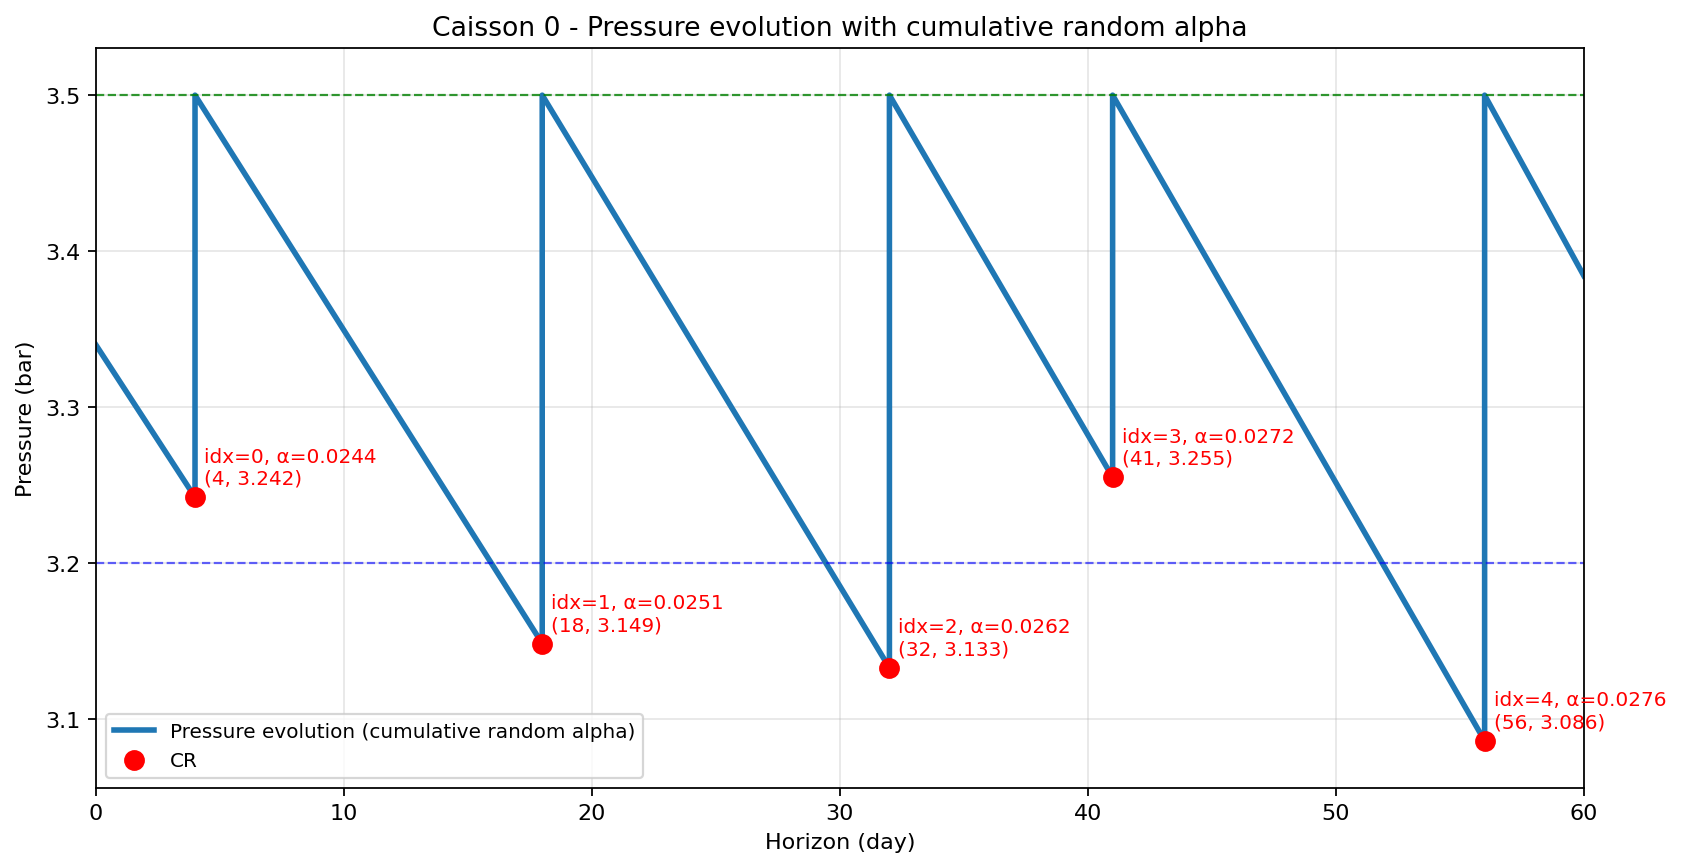

图已保存到：output/caisson_0_cumulative_random_alpha.png


In [ ]:
# draw pressure profile if grouping results are applied
# here，same initial pressure as before but real alpha values: alpha_k = alpha_k-1 * (1+delta), delta is random

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

planning = pd.read_csv("clustering_result.csv")
T = 60
caisson_idx = 0

tasks = planning[(planning["CSEM"] == caisson_idx) & (planning["OPERATION"] == "x")].copy()
if tasks.empty:
    raise ValueError(f"没有找到 CSEM={caisson_idx} 的 x 任务")

tasks = tasks.sort_values("CENTER").reset_index(drop=True)

alpha_base = float(tasks.iloc[0]["ALPHA"])
initial_p = float(tasks.iloc[0]["INITIALP"])

rng = np.random.default_rng(42)

x = [0]
y = [initial_p]

current_day = 0
current_p = initial_p
current_alpha = alpha_base   # 注意：这是递推基准

task_days = []
task_pressures_before = []
task_labels = []
used_alphas = []
used_deltas = []

for _, row in tasks.iterrows():
    center_day = int(row["CENTER"])
    task_index = int(row["INDEX"])

    # 在前一个 actual alpha 基础上更新
    delta = rng.uniform(0.01, 0.1)
    current_alpha = current_alpha * (1 + delta)

    # 用更新后的 current_alpha 跑这一段
    p_before_task = current_p - current_alpha * (center_day - current_day)

    x.append(center_day)
    y.append(p_before_task)

    # 同一天竖直跳回 3.5
    x.append(center_day)
    y.append(3.5)

    task_days.append(center_day)
    task_pressures_before.append(p_before_task)
    task_labels.append(task_index)
    used_alphas.append(current_alpha)
    used_deltas.append(delta)

    current_day = center_day
    current_p = 3.5

# 最后一段，从最后一个 center 到 T，也继续用“上一段 alpha 再更新一次”
if current_day < T:
    delta = rng.uniform(0.01, 0.1)
    current_alpha = current_alpha * (1 + delta)
    final_p = current_p - current_alpha * (T - current_day)

    x.append(T)
    y.append(final_p)
    used_alphas.append(current_alpha)
    used_deltas.append(delta)

fig, ax = plt.subplots(figsize=(12, 6), dpi=160)

ax.plot(x, y, color="#1f77b4", linewidth=2.5, label="Pressure evolution (cumulative random alpha)")
ax.scatter(task_days, task_pressures_before, color="red", s=70, zorder=5, label="CR")

# for day, p_before, idx, delta, a in zip(task_days, task_pressures_before, task_labels, used_deltas[:len(task_days)], used_alphas[:len(task_days)]):
#     ax.annotate(
#         f"idx={idx}\nδ={delta:.3f}\nα={a:.4f}",
#         xy=(day, p_before),
#         xytext=(4, 6),
#         textcoords="offset points",
#         fontsize=8,
#         color="red"
#     )

for day, p_before, idx, alpha in zip(task_days, task_pressures_before, task_labels, used_alphas):
    ax.annotate(
        f"idx={idx}, α={alpha:.4f}\n({day}, {p_before:.3f})",
        xy=(day, p_before),
        xytext=(4, 6),
        textcoords="offset points",
        fontsize=9,
        color="red"
    )

ax.axhline(3.5, color="green", linestyle="--", linewidth=1, alpha=0.8)
ax.axhline(3.0, color="red", linestyle="--", linewidth=1, alpha=0.5)
ax.axhline(3.2, color="blue", linestyle="--", linewidth=1, alpha=0.6)

ax.set_title(f"Caisson {caisson_idx} - Pressure evolution with cumulative random alpha")
ax.set_xlabel("Horizon (day)")
ax.set_ylabel("Pressure (bar)")
ax.set_xlim(0, T)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)

ymin = min(y) - 0.03
ymax = max(y) + 0.03
ax.set_ylim(ymin, ymax)

os.makedirs("output", exist_ok=True)
save_path = f"output/caisson_{caisson_idx}_cumulative_random_alpha.png"
plt.savefig(save_path, bbox_inches="tight")
plt.show()

print(f"图已保存到：{save_path}")